---
title: "Special Relativity — Level 2"
short_title: "12 Special Relativity"
numbering:
  heading_2: true
  equation: true
---

# Special Relativity

:::{seealso} Math for this topic
- [M6: Linear algebra](../math/06-linear-algebra.ipynb)
- [M7: Legendre transforms, phase portraits and hyperbolic functions](../math/07-legendre-phase-hyperbolic.ipynb)
:::

:::{tip} Where this sits on the ladder
| Level | Text | What you do |
|---|---|---|
| 1 | Tipler & Mosca, ch. 39 (relativity chapter) | Time dilation and length contraction with numbers |
| **2** | **Taylor, ch. 15** | **Lorentz transformations as matrices, four-vectors, invariants, relativistic energy and momentum** |
| 3 | Goldstein, ch. 7; Jackson, ch. 11–12 | Covariant Lagrangians, relativistic electrodynamics |

The new skill at this level: treating space and time as one four-dimensional geometry, where invariants do the work that conservation laws did before

Math for this topic: M6 (matrices, tensors) and M7 (hyperbolic functions).
:::

Builds on the momentum notes (collisions) and M7 (rapidity). This topic must come before E&M topic 10 in the study order. Exercises have separate hint and answer dropdowns.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from scipy.integrate import solve_ivp, quad

plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (7, 4.6),
                     "axes.grid": True, "grid.alpha": 0.3})
g = 9.81  # m/s^2

## The Two Postulates

1. The laws of physics take the same form in every inertial frame.
2. The speed of light in vacuum, $c$, is the same in every inertial frame.

The first is Galileo's principle; Newton's mechanics already satisfies it. The second is the surprise, and it forces time itself to be frame dependent.

## The Lorentz Transformation

Let frame $\mathcal{S}'$ move at velocity $v$ along $x$ relative to $\mathcal{S}$, with origins coinciding at $t = t' = 0$. Requiring that a light flash spreads at speed $c$ in both frames, and that the transformation be linear, gives

$$
ct' = \gamma\left(ct - \beta x\right), \qquad x' = \gamma\left(x - \beta ct\right), \qquad y' = y, \quad z' = z,
$$ (eq-lorentz)

with

$$
\beta = \frac vc, \qquad \gamma = \frac{1}{\sqrt{1 - \beta^2}} .
$$

Measuring time in length units ($x^0 = ct$) makes the symmetry between space and time visible. As a matrix acting on $(x^0, x^1)$,

$$
\Lambda = \begin{pmatrix}\gamma & -\gamma\beta\\ -\gamma\beta & \gamma\end{pmatrix} = \begin{pmatrix}\cosh u & -\sinh u\\ -\sinh u & \cosh u\end{pmatrix}, \qquad \beta = \tanh u .
$$ (eq-boost-matrix)

The **rapidity** $u$ (M7) makes a boost look like a rotation with hyperbolic functions. Two boosts along the same line combine by **adding rapidities**, which is why velocities add by the $\tanh$ formula,

$$
v_{\text{total}} = \frac{v_1 + v_2}{1 + v_1v_2/c^2} ,
$$

and never exceed $c$. For $v\ll c$, $\gamma\approx1$ and {eq}`eq-lorentz` reduces to the Galilean $x' = x - vt$, $t' = t$.

In [2]:
# Boosts compose by adding rapidities
u1, u2 = sp.symbols("u1 u2", real=True)
B = lambda u: sp.Matrix([[sp.cosh(u), -sp.sinh(u)], [-sp.sinh(u), sp.cosh(u)]])
print("B(u1) B(u2) - B(u1 + u2) =", sp.simplify((B(u1) * B(u2) - B(u1 + u2)).applyfunc(lambda e: e.rewrite(sp.exp))))

beta = sp.symbols("beta", positive=True)
Lam = sp.Matrix([[1, -beta], [-beta, 1]]) / sp.sqrt(1 - beta**2)
g = sp.diag(1, -1)                            # metric for (ct, x)
print("Lambda^T g Lambda == g:", sp.simplify(Lam.T * g * Lam - g) == sp.zeros(2, 2))

B(u1) B(u2) - B(u1 + u2) = Matrix([[0, 0], [0, 0]])
Lambda^T g Lambda == g: True


## Consequences

**Relativity of simultaneity.** Two events at the same $t$ but different $x$ have different $t'$, by {eq}`eq-lorentz`. "Now" depends on the observer.

**Time dilation.** A clock at rest in $\mathcal{S}'$ ticks with interval $\Delta\tau$ in its own frame (its **proper time**). In $\mathcal{S}$ the same ticks are separated by $\Delta t = \gamma\Delta\tau$: moving clocks run slow.

**Length contraction.** A rod at rest in $\mathcal{S}'$ with length $L_0$ (its **proper length**) has length $L = L_0/\gamma$ when measured in $\mathcal{S}$, where both ends are located at the same $t$.

A **spacetime diagram** shows all three at once. A boosted frame's time and space axes tilt toward the light line $x = ct$ like scissors closing. Lines of constant $t'$ (simultaneity in $\mathcal{S}'$) are tilted, so the two frames slice spacetime into "now" differently.

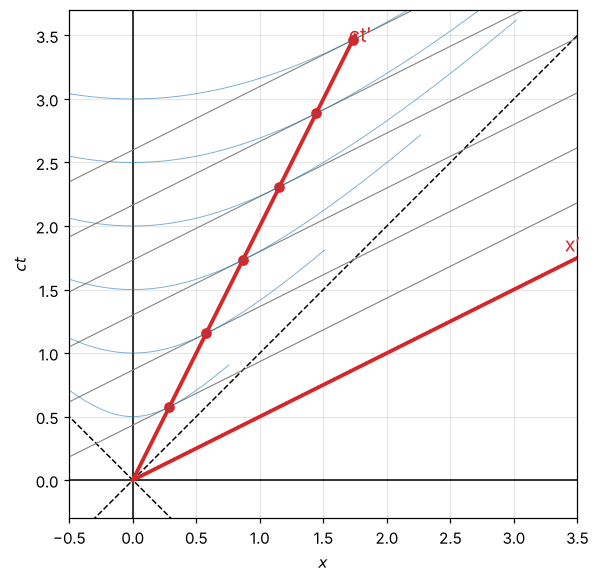

In [3]:
#| label: fig-spacetime
#| caption: Spacetime diagram for β = 0.5. The S′ axes (red) are tilted symmetrically toward the light line (dashed). Gray lines are constant-t′ slices; a clock at rest in S′ moves along the ct′ axis, and its ticks (dots, at proper-time intervals) sit on hyperbolas c²t² − x² = const.
beta = 0.5
gam = 1 / np.sqrt(1 - beta**2)
fig, ax = plt.subplots(figsize=(6, 6))
L = np.linspace(-0.5, 3.5, 2)
ax.plot(L, L, "k--", lw=1); ax.plot(-L, L, "k--", lw=1)
ax.axhline(0, color="k", lw=1); ax.axvline(0, color="k", lw=1)
s = np.linspace(0, 3.5, 2)
ax.plot(beta * s, s, "tab:red", lw=2.5); ax.text(beta * 3.4, 3.45, "ct′", color="tab:red", fontsize=13)
ax.plot(s, beta * s, "tab:red", lw=2.5); ax.text(3.4, beta * 3.4 + 0.1, "x′", color="tab:red", fontsize=13)
for tp in np.arange(0.5, 3.5, 0.5):
    xx = np.linspace(-0.5, 3.5, 2)
    ax.plot(xx, beta * xx + tp / gam, color="gray", lw=0.7)
for tau in np.arange(0.5, 3.5, 0.5):
    ax.plot(gam * beta * tau, gam * tau, "o", color="tab:red", ms=6)
    uu = np.linspace(-1.2, 1.2, 100)
    ax.plot(tau * np.sinh(uu), tau * np.cosh(uu), color="tab:blue", lw=0.6, alpha=0.6)
ax.set_xlim(-0.5, 3.5); ax.set_ylim(-0.3, 3.7); ax.set_aspect("equal")
ax.set_xlabel("$x$"); ax.set_ylabel("$ct$"); plt.show()

### Exercises

1. Muons made high in the atmosphere have a mean lifetime of $2.2\ \mu$s in their rest frame. At $v = 0.995c$, how far does a typical muon travel before decaying, with and without time dilation?
2. A spaceship moving at $0.8c$ fires a probe forward at $0.8c$ relative to the ship. How fast is the probe moving relative to Earth?
3. Show that $\Lambda^{\mathsf T}g\,\Lambda = g$ for {eq}`eq-boost-matrix` with $g = \operatorname{diag}(1, -1)$ (the code above checks it). What does this equation say in words?

:::{dropdown} Hints
1. $\gamma\approx10$ at $0.995c$.
2. Use the velocity-addition formula.
3. Compare with $R^{\mathsf T}R = I$ for rotations.
:::

:::{dropdown} Answers
1. Without dilation, $c\tau\approx0.66$ km. With it, $\gamma c\tau\approx6.6$ km, which is why muons reach the ground.
2. $1.6c/1.64\approx0.976c$.
3. It says boosts preserve the quantity $\vec{x}^{\mathsf T}g\,\vec{x} = (ct)^2 - x^2$, just as rotations preserve $\vec{x}^{\mathsf T}\vec{x}$. Lorentz transformations are the rotations of spacetime.
:::

## Four-Vectors and the Invariant Interval

Every inertial observer agrees on the **interval** between two events,

$$
\Delta s^2 = (c\Delta t)^2 - \Delta x^2 - \Delta y^2 - \Delta z^2 ,
$$ (eq-interval)

even though they disagree about $\Delta t$ and $\Delta x$ separately. Write it with the **metric** $g = \operatorname{diag}(1, -1, -1, -1)$ as $\Delta s^2 = \Delta X^{\mathsf T}g\,\Delta X$. Its sign classifies the separation:

| $\Delta s^2$ | Separation | Meaning |
|---|---|---|
| $> 0$ | timelike | one event can cause the other; $\Delta s/c$ is the proper time between them |
| $= 0$ | lightlike | connected by a light signal |
| $< 0$ | spacelike | no causal connection; their time order depends on the frame |

A **four-vector** is any set of four quantities that transforms like $(ct, x, y, z)$ under {eq}`eq-lorentz`. Its "length squared" $A^{\mathsf T}gA$ is the same in every frame, and so is the "dot product" $A^{\mathsf T}gB$ of any two four-vectors. This is the tensor idea from M6, with $g$ replacing the identity.

### Four-velocity and four-momentum

Proper time $d\tau = dt/\gamma$ is invariant, so differentiating position with respect to it gives a four-vector, the **four-velocity** $U = dX/d\tau = \gamma(c, \vec{v})$, with $U^{\mathsf T}gU = c^2$. Multiplying by the mass gives the **four-momentum**:

$$
P = mU = \left(\frac Ec,\ \vec{p}\right), \qquad E = \gamma mc^2, \qquad \vec{p} = \gamma m\vec{v} .
$$ (eq-four-momentum)

Its invariant length is the mass:

$$
P^{\mathsf T}gP = \frac{E^2}{c^2} - p^2 = m^2c^2 \qquad\Longleftrightarrow\qquad E^2 = (pc)^2 + (mc^2)^2 .
$$ (eq-energy-momentum)

At rest, $E = mc^2$, the **rest energy**. For $v\ll c$, $E\approx mc^2 + \tfrac12mv^2$, so the kinetic energy $T = (\gamma - 1)mc^2$ reduces to the Newtonian form. Massless particles have $E = pc$ and move at $c$.

In [4]:
# The invariant really is invariant: boost a four-momentum and recompute E^2 - (pc)^2
m, c, v, V = sp.symbols("m c v V", positive=True)
gam_v = 1 / sp.sqrt(1 - v**2 / c**2)
P = sp.Matrix([gam_v * m * c, gam_v * m * v])               # (E/c, p) for a particle moving at v
GV = 1 / sp.sqrt(1 - V**2 / c**2)
Boost = GV * sp.Matrix([[1, -V / c], [-V / c, 1]])         # observer moving at V
Pp = Boost * P
g2 = sp.diag(1, -1)
print("P^T g P  :", sp.simplify((P.T * g2 * P)[0]))
print("P'^T g P':", sp.simplify((Pp.T * g2 * Pp)[0]))

P^T g P  : c**2*m**2
P'^T g P': c**2*m**2


## Relativistic Collisions

In every collision, the **total four-momentum is conserved**: energy and three-momentum together. Rest mass is **not** conserved separately; kinetic energy can become mass and back.

The most useful trick is to evaluate the invariant $P_{\text{tot}}^{\mathsf T}gP_{\text{tot}}$ in whichever frame is easiest. In the center-of-mass frame it is $(E_{\text{cm}}/c)^2$, the energy available to make new particles.

::::{prf:example} Threshold for making a new particle
:label: ex-threshold

A proton beam hits protons at rest. What is the minimum beam kinetic energy for $p + p\to p + p + \pi^0$? ($m_pc^2 = 938.3$ MeV, $m_\pi c^2 = 135.0$ MeV.)

:::{dropdown} Solution
At threshold, the products are created at rest in the CM frame, so $E_{\text{cm}} = (2m_p + m_\pi)c^2$. In the lab, the beam has energy $E$ and the target $m_pc^2$, so

$$
\frac{E_{\text{cm}}^2}{c^2} = \left(\frac{E + m_pc^2}{c}\right)^2 - p^2 = 2m_p^2c^2 + 2Em_p .
$$

Setting the two equal and solving gives $E$, and the kinetic energy is

$$
T_{\text{th}} = E - m_pc^2 = \frac{(2m_p + m_\pi)^2 - (2m_p)^2}{2m_p}c^2 \approx 280\ \text{MeV} ,
$$

about twice the pion's rest energy. Much of the beam energy is used up keeping the center of mass moving, the relativistic version of the collider argument in the momentum notes.
:::
::::

In [5]:
mp, mpi = 938.272, 134.977          # MeV/c^2
T_th = ((2 * mp + mpi)**2 - (2 * mp)**2) / (2 * mp)
print(f"threshold kinetic energy: {T_th:.1f} MeV  (pion rest energy {mpi:.1f} MeV)")

threshold kinetic energy: 279.7 MeV  (pion rest energy 135.0 MeV)


## Constant Proper Acceleration

A rocket whose passengers always feel the same acceleration $a$ (measured in its momentary rest frame) does **not** have $dv/dt$ constant in the launch frame. Its rapidity grows at a constant rate, $u = a\tau/c$, so with M7's hyperbolic functions,

$$
v = c\tanh\frac{a\tau}{c}, \qquad t = \frac ca\sinh\frac{a\tau}{c}, \qquad x = \frac{c^2}{a}\left(\cosh\frac{a\tau}{c} - 1\right) .
$$

The world line is a hyperbola in the spacetime diagram (**hyperbolic motion**). The speed approaches $c$ but never reaches it, while the travelers' own elapsed time $\tau$ grows only logarithmically with the distance covered.

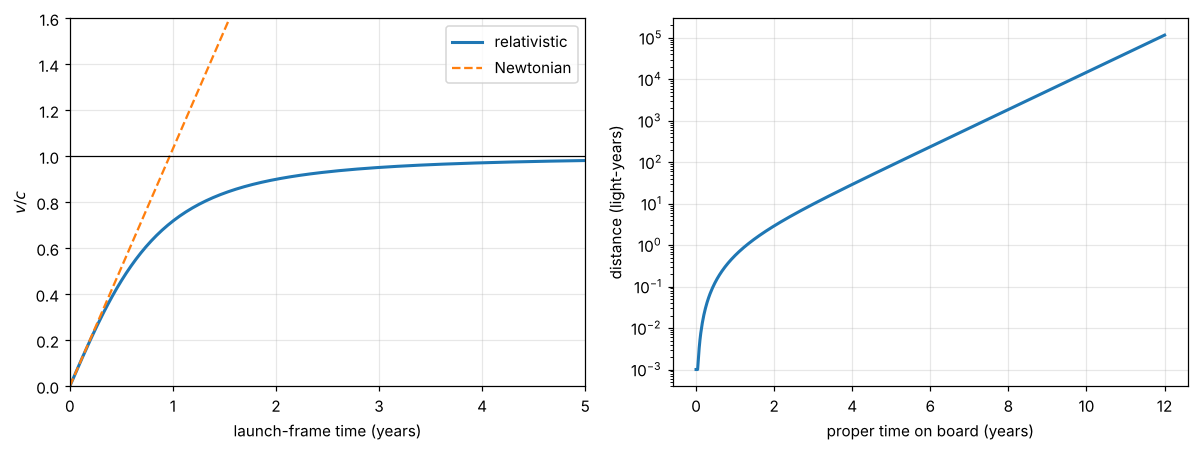

after 10 years on board: distance 14,789 ly, launch-frame time 14,790 yr


In [6]:
#| label: fig-hyperbolic-motion
#| caption: A rocket with constant proper acceleration 1 g. Left, its speed approaches c, while the Newtonian prediction (dashed) passes c in under a year. Right, distance covered versus the travelers' own elapsed time; the scale is logarithmic, so several years of proper time cover thousands of light-years.
c = 2.998e8; a = 9.81
yr = 3.156e7; ly = c * yr
tau = np.linspace(0, 12 * yr, 600)
t = c / a * np.sinh(a * tau / c)
v = c * np.tanh(a * tau / c)
x = c**2 / a * (np.cosh(a * tau / c) - 1)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].plot(t / yr, v / c, lw=2, label="relativistic")
axes[0].plot(t / yr, a * t / c, "--", lw=1.5, label="Newtonian")
axes[0].set_xlim(0, 5); axes[0].set_ylim(0, 1.6); axes[0].axhline(1, color="k", lw=0.8)
axes[0].set_xlabel("launch-frame time (years)"); axes[0].set_ylabel("$v/c$"); axes[0].legend()
axes[1].semilogy(tau / yr, np.maximum(x / ly, 1e-3), lw=2)
axes[1].set_xlabel("proper time on board (years)"); axes[1].set_ylabel("distance (light-years)")
plt.tight_layout(); plt.show()
print(f"after 10 years on board: distance {c**2/a*(np.cosh(a*10*yr/c)-1)/ly:,.0f} ly, launch-frame time {c/a*np.sinh(a*10*yr/c)/yr:,.0f} yr")

:::{note} Relativity in Lagrangian form (Level 3 preview)
A free particle's relativistic Lagrangian is $\mathcal{L} = -mc^2/\gamma = -mc^2\sqrt{1 - v^2/c^2}$. Its action is $-mc^2$ times the elapsed proper time, so Hamilton's principle says a free particle follows the path of **maximum proper time** between two events. That is the "twin paradox" result stated as a variational principle, and it carries straight over to general relativity.
:::

### Exercises

1. Find the speed of a particle whose kinetic energy equals its rest energy.
2. A photon of energy $E_\gamma$ strikes an electron at rest. Show that the photon cannot simply be absorbed (with the electron as the only product).
3. An electron and a positron, each with energy $E$, collide head-on. What is the largest rest mass that a single product particle could have? Compare with a positron of energy $2E$ hitting an electron at rest, for $E\gg m_ec^2$.

:::{dropdown} Hints
1. $T = (\gamma - 1)mc^2 = mc^2$.
2. Compute the invariant mass of the initial state and compare it with $m_e$.
3. In the head-on case the lab is the CM frame. For the fixed target, use $E_{\text{cm}}^2 = 2m_e^2c^4 + 2Em_ec^2$ with the beam energy.
:::

:::{dropdown} Answers
1. $\gamma = 2$, so $v = \tfrac{\sqrt3}{2}c\approx0.87c$.
2. The initial invariant mass satisfies $M^2c^4 = m_e^2c^4 + 2E_\gamma m_ec^2 > m_e^2c^4$ for any $E_\gamma > 0$, so the final state cannot be a single electron.
3. Head-on: $Mc^2 = 2E$. Fixed target with beam $2E$: $E_{\text{cm}}\approx\sqrt{4Em_ec^2}$, far smaller. This is why high-energy physics uses colliding beams.
:::

## Summary

- Lorentz boosts mix $ct$ and $x$; with rapidity they are hyperbolic rotations, and rapidities add.
- Moving clocks run slow, moving rods are short, and simultaneity depends on the frame.
- The interval $(c\Delta t)^2 - \Delta\vec{x}^2$ is invariant; four-vectors transform like $(ct, \vec{x})$ and have invariant lengths and dot products via the metric $g$.
- Four-momentum $(E/c, \vec{p})$ has invariant length $mc$: $E^2 = (pc)^2 + (mc^2)^2$.
- In collisions total four-momentum is conserved, and the invariant mass sets thresholds.
- Constant proper acceleration gives hyperbolic motion, with $v = c\tanh(a\tau/c)$.

## Appendix: MyST patterns

Same conventions as the rest of the book: `prf:` directives for definitions, theorems and examples; `:::{dropdown}` for solutions, hints and answers; `$$ ... $$ (label)` with `` {eq}`label` `` for equations; and code cells tagged `hide-input` that start with `#| label:` and `#| caption:` lines.